# Lab 4 — Notebook 2: Instance Segmentation · Carparts-seg

**Group members:** *Elias Hawkins & Davin Matias*

**Task:** Outline each visible car part with a polygon  
**Dataset:** `carparts-seg.yaml`  
**Starting weights:** `yolo26n-seg.pt`

**Constraints (from the lab manual):**
- Ultralytics YOLO on Google Colab with a T4 GPU
- Nano (`n`) model only
- `imgsz=640`, `batch=16`, `seed=0`
- Epochs: **15–30** (you choose within this range)
- Save training runs to Google Drive
- Predictions and reflection answers must be your own writing (no AI)

Work top to bottom. Write each **Prediction** *before* you run the code that follows it.


---
## Step 0: Setup and data check

Install Ultralytics, mount Drive, load the dataset, and verify it matches the lab tables.


### Install and imports


In [ ]:
# Runtime → Change runtime type → T4 GPU (recommended)
!pip -q install ultralytics


In [ ]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ultralytics
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

print("Ultralytics:", ultralytics.__version__)
ultralytics.checks()


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (8 CPUs, 51.0 GB RAM, 0.1/235.7 GB disk)


### Mount Google Drive (so disconnects don't erase training runs)


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

# Change this if you want a different save location on Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/IT480_Lab4")
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
print("Saving runs under:", DRIVE_ROOT)


Mounted at /content/drive
Saving runs under: /content/drive/MyDrive/IT480_Lab4


### Config for this notebook

Expected dataset (from the lab manual):

| Property | Value |
| --- | --- |
| Classes | 23 car parts (doors, lights, bumper, hood, wheel, ...) |
| Images | 3,833 total: 3,156 train / 401 val / 276 test |
| Label format | `class x1 y1 x2 y2 ... xn yn` |


In [ ]:
# ---- Notebook config ----
TASK = "segment"
DATA_YAML = "carparts-seg.yaml"
WEIGHTS = "yolo26n-seg.pt"
IMGSZ = 640
BATCH = 16
SEED = 0

# YOU choose epochs within 15–30 (fill Prediction 2 before changing this)
EPOCHS = 30  # TODO: set your chosen epoch count

PROJECT_DIR = DRIVE_ROOT / "segmentation"
RUN_NAME = "seg_run"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Task={TASK} | data={DATA_YAML} | weights={WEIGHTS}")
print(f"epochs={EPOCHS} | imgsz={IMGSZ} | batch={BATCH} | seed={SEED}")
print(f"project={PROJECT_DIR} | name={RUN_NAME}")


Task=segment | data=carparts-seg.yaml | weights=yolo26n-seg.pt
epochs=30 | imgsz=640 | batch=16 | seed=0
project=/content/drive/MyDrive/IT480_Lab4/segmentation | name=seg_run


### Download / locate the dataset and print class names + split sizes


In [ ]:
# check_det_dataset downloads the zip on first use and returns parsed YAML fields
data_info = check_det_dataset(DATA_YAML)

DATA_ROOT = Path(data_info["path"])
NAMES = data_info["names"]
if isinstance(NAMES, list):
    NAMES = {i: n for i, n in enumerate(NAMES)}

print("Dataset root:", DATA_ROOT)
print("Class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")
print("Number of classes:", len(NAMES))


def list_images(split: str):
    split_rel = data_info.get(split)
    if not split_rel:
        return []
    # YAML values are relative to DATA_ROOT (e.g. "images/train")
    split_dir = Path(split_rel)
    if not split_dir.is_absolute():
        split_dir = DATA_ROOT / split_dir
    if not split_dir.exists():
        return []
    return sorted(
        p for p in split_dir.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )

train_imgs = list_images("train")
val_imgs = list_images("val")
test_imgs = list_images("test")

print("\nImage counts:")
print(f"  train: {len(train_imgs)}")
print(f"  val:   {len(val_imgs)}")
print(f"  test:  {len(test_imgs)}")
print(f"  total: {len(train_imgs) + len(val_imgs) + len(test_imgs)}")

# Soft checks against the lab tables (edit EXPECTED if the manual differs)
EXPECTED = {'train': 3156, 'val': 401, 'test': 276}
for split, n in EXPECTED.items():
    got = {"train": len(train_imgs), "val": len(val_imgs), "test": len(test_imgs)}[split]
    status = "OK" if got == n else f"MISMATCH (expected {n})"
    print(f"  check {split}: {got} -> {status}")



WARNING ⚠️ Dataset 'carparts-seg.yaml' images not found, missing path '/content/datasets/carparts-seg/images/val'
Unzipping /content/datasets/carparts-seg.zip to /content/datasets/carparts-seg...: 100% ━━━━━━━━━━━━ 7675/7675 3.7Kfiles/s 2.1s
Dataset download success ✅ (3.8s), saved to /content/datasets

Dataset root: /content/datasets/carparts-seg
Class names:
  0: back_bumper
  1: back_door
  2: back_glass
  3: back_left_door
  4: back_left_light
  5: back_light
  6: back_right_door
  7: back_right_light
  8: front_bumper
  9: front_door
  10: front_glass
  11: front_left_door
  12: front_left_light
  13: front_light
  14: front_right_door
  15: front_right_light
  16: hood
  17: left_mirror
  18: object
  19: right_mirror
  20: tailgate
  21: trunk
  22: wheel
Number of classes: 23

Image counts:
  train: 3156
  val:   401
  test:  276
  total: 3833
  check train: 3156 -> OK
  check val: 401 -> OK
  check test: 276 -> OK


### Display ≥3 images with ground-truth labels


In [ ]:
import cv2

# Distinct BGR colors for overlays
colors = [
    (255, 56, 56), (255, 157, 151), (255, 112, 31), (255, 178, 29),
    (207, 210, 49), (72, 249, 10), (146, 204, 23), (61, 219, 134),
    (26, 147, 52), (0, 212, 187), (44, 153, 168), (0, 194, 255),
    (52, 69, 147), (70, 70, 70), (153, 153, 153), (255, 255, 255),
]

def show_ground_truth(img_paths, names, n=3, seed=0):
    """Display n images with ground-truth labels drawn on them and print their class names."""
    rng = random.Random(seed)
    chosen = rng.sample(list(img_paths), k=min(n, len(img_paths)))

    fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))
    if len(chosen) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, chosen):
        img_path = Path(img_path)
        # labels/ mirrors images/ (train|val|test)
        label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        detected_classes = []

        # Segmentation labels: class x1 y1 x2 y2 ... (normalized polygon)
        if label_path.exists():
            for line in label_path.read_text().strip().splitlines():
                parts = line.split()
                if len(parts) < 7:
                    continue
                cls_id = int(float(parts[0]))
                detected_classes.append(names.get(cls_id, str(cls_id)))
                coords = list(map(float, parts[1:]))
                pts = np.array(coords, dtype=np.float32).reshape(-1, 2)
                pts[:, 0] *= w
                pts[:, 1] *= h
                pts = pts.astype(np.int32)
                color = colors[cls_id % len(colors)]
                cv2.polylines(img, [pts], isClosed=True, color=color, thickness=2)
                x1, y1 = pts.min(axis=0)
                cv2.putText(
                    img,
                    names.get(cls_id, str(cls_id)),
                    (int(x1), max(15, int(y1) - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    color,
                    2,
                    cv2.LINE_AA,
                )

        print(f"Image: {img_path.name}")
        print(f"Classes: {sorted(list(set(detected_classes)))}\n")
        ax.imshow(img)
        ax.set_title(img_path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return chosen

Image: train217_jpg.rf.20651649ac21e93d25f97f76eaa5d277.jpg
Classes: []

Image: train83_jpg.rf.775ff5fef920a46798cd8ad7bf7e5501.jpg
Classes: ['back_bumper', 'back_glass', 'back_left_light', 'back_right_light', 'trunk', 'wheel']

Image: train242_jpg.rf.92e4003d7e92d873c9d58274227086fb.jpg
Classes: ['back_bumper', 'back_glass', 'back_light']



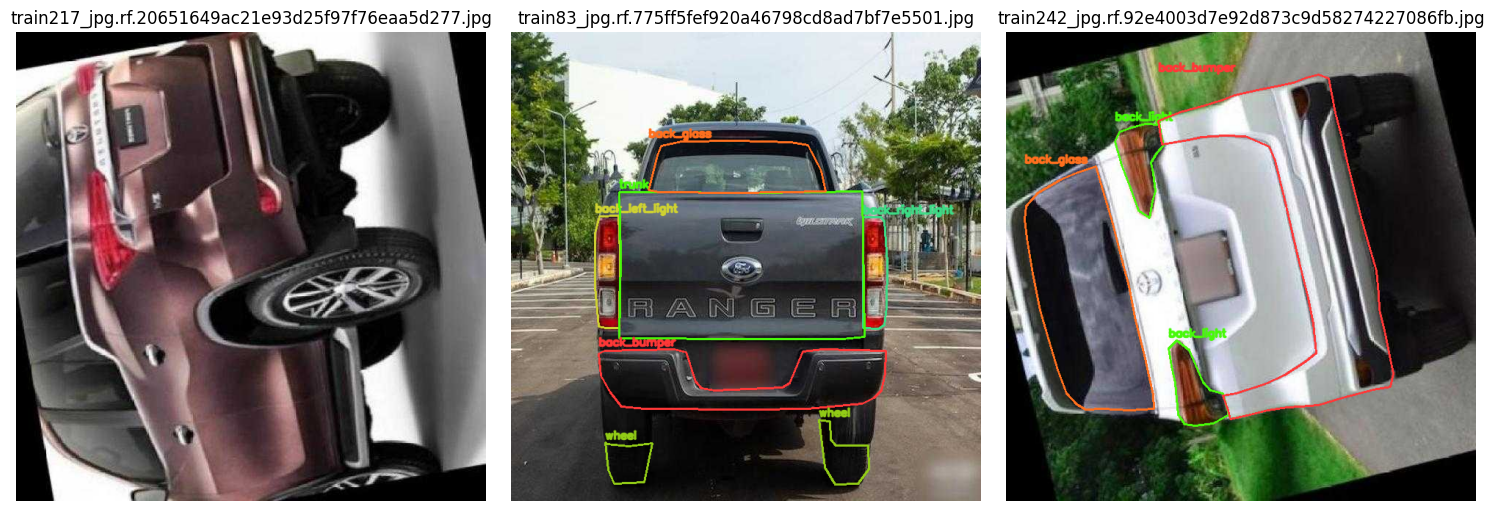

Shown classes: [[], ['back_bumper', 'back_glass', 'back_left_light', 'back_right_light', 'trunk', 'wheel'], ['back_bumper', 'back_glass', 'back_light']]
Number of splits per pic: [0, 7, 4]


In [ ]:
gt_examples = show_ground_truth(val_imgs, NAMES, n=3, seed=0)

shown_classes = []
split_counts = []
for p in gt_examples:
    label_path = Path(str(p).replace("/images/", "/labels/")).with_suffix(".txt")
    classes = set()
    splits_in_pic = 0
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) >= 7:
                classes.add(NAMES.get(int(float(parts[0]))))
                splits_in_pic += 1
    shown_classes.append(sorted(list(classes)))
    split_counts.append(splits_in_pic)

print("Shown classes:", shown_classes)
print("Number of splits per pic:", split_counts)

### Checkpoint 1: The data is what you expect

**Write your answer below (your own words):**
- Do the printed class names and split counts match the lab tables?
- Do the ground-truth overlays line up with the objects?

- *The printed classes names match the lab tables, and the split counts match the images displayed.*
- *The ground-truth overlays line up with the objects, but only when the objects are detected.*


---
## Step 1: Baseline (pretrained model, no training)

Run the COCO-pretrained model **as-is** on five validation images.


### Prediction 1 *(write BEFORE running the baseline)*

What do you expect the COCO-pretrained model to get right and wrong on this dataset? Why?

*We expect the COCO-pretrained model to get lights right, because of their bright contrast to the rest of the car. We also expect the model to mix up the trunk and the hood because of similar surrounding parts.*


In [ ]:
def show_predictions(model, img_paths, title_prefix="pred"):
    """Run model on images and display annotated results with matplotlib (Colab-safe)."""
    results = model.predict(source=[str(p) for p in img_paths], imgsz=640, verbose=False)

    fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 5))
    if len(results) == 1:
        axes = [axes]

    for ax, r, p in zip(axes, results, img_paths):
        # results.plot() returns a BGR ndarray
        annotated = r.plot()
        ax.imshow(annotated[:, :, ::-1])
        ax.set_title(f"{title_prefix}: {Path(p).name}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return results


In [ ]:
baseline = YOLO(WEIGHTS)

print("Pretrained model class names:")
print(baseline.names)
print("Number of pretrained classes:", len(baseline.names))


Pretrained model class names:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard',

In [ ]:
print("\nDataset class names for comparison:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")
print("\nNote: COCO has a 'car' class but no car-part classes.")



Dataset class names for comparison:
  0: back_bumper
  1: back_door
  2: back_glass
  3: back_left_door
  4: back_left_light
  5: back_light
  6: back_right_door
  7: back_right_light
  8: front_bumper
  9: front_door
  10: front_glass
  11: front_left_door
  12: front_left_light
  13: front_light
  14: front_right_door
  15: front_right_light
  16: hood
  17: left_mirror
  18: object
  19: right_mirror
  20: tailgate
  21: trunk
  22: wheel

Note: COCO has a 'car' class but no car-part classes.


Baseline images: ['train136_jpg.rf.f6a49d79279946ccbf9b283e0a7ff803.jpg', 'train221_jpg.rf.f52fdf9f48cca8124bb5a16629b38522.jpg', 'train316_jpg.rf.4452d0d2dde6b116824d34c9f7c4e737.jpg', 'train4_jpg.rf.b05aae1597b05e7e843528913f6e863d.jpg', 'train242_jpg.rf.92e4003d7e92d873c9d58274227086fb.jpg']


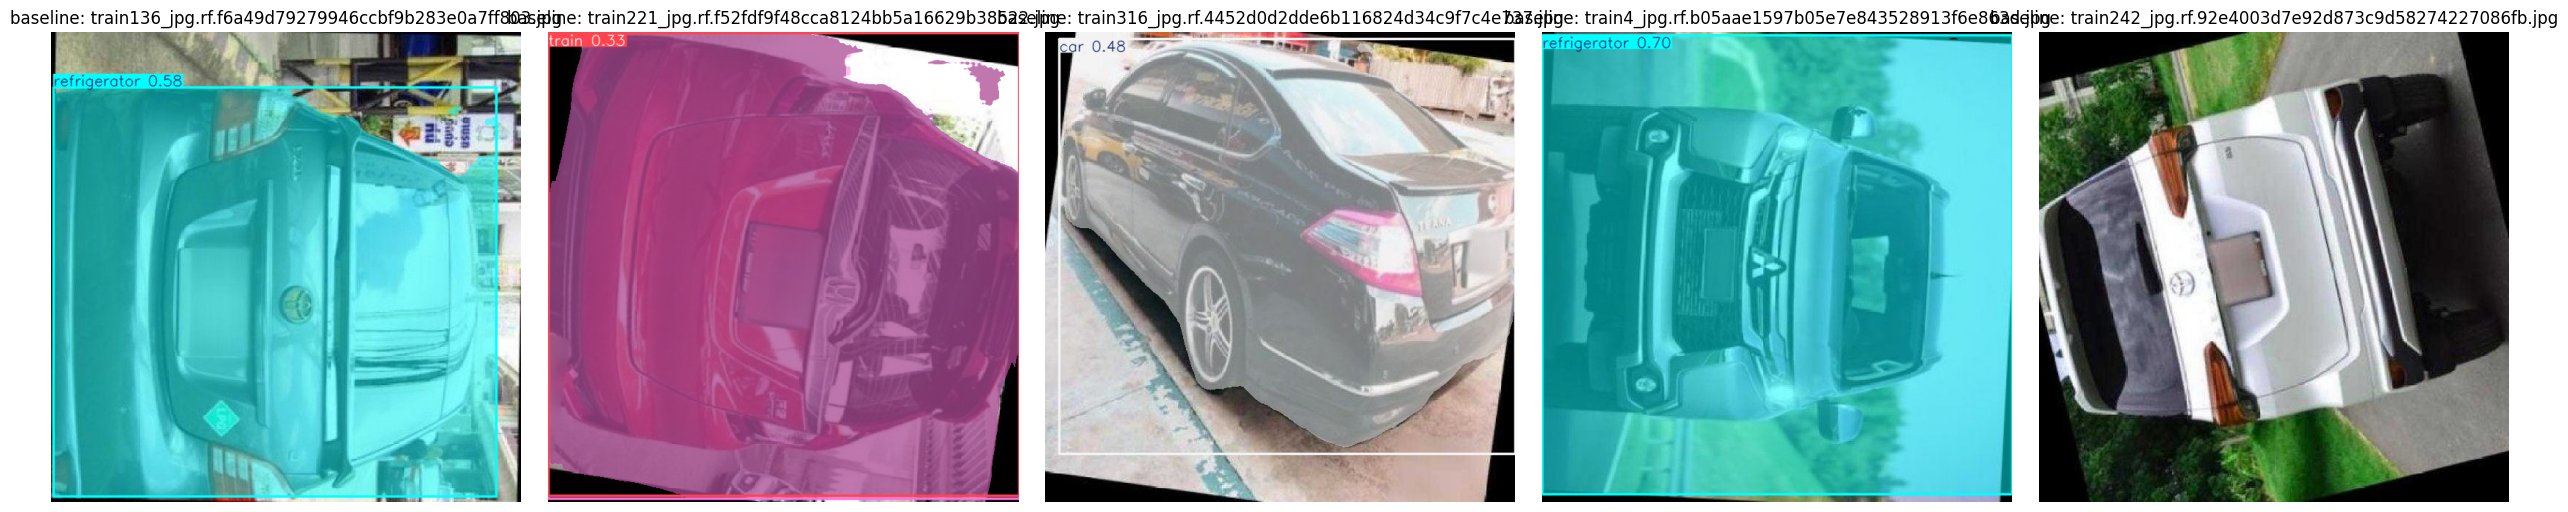

In [ ]:
# Five validation images (fixed seed so your write-up is reproducible)
rng = random.Random(80)
baseline_imgs = rng.sample(val_imgs, k=min(5, len(val_imgs)))
print("Baseline images:", [Path(p).name for p in baseline_imgs])

baseline_results = show_predictions(baseline, baseline_imgs, title_prefix="baseline")


### Checkpoint 2: Why the baseline fails

**Write your answer below (your own words):**
- Compare the pretrained model's class names (or keypoint count) with the dataset's. What went wrong in your five images?
- Explain why a baseline mAP computed on this dataset with the pretrained model would be meaningless. Hint: what does class 0 mean to each one?

**Task-specific:** COCO has a "car" class but no car parts. What did the baseline outline instead?

- *For the 5 images, the most egregious error was predicting that a sideways car was a refrigerator. It also had trouble labeling images at all with a prediction if it was not upright.*

- *A baseline mAP computed on this dataset with the pretrained model would be meaningless because class 0 in each mean different things--one for "back_bumper" and another for "person"*

- *COCO has a car class and only outlined a detection box around the whole object. Without car part classes, it does not outline any specific part of the car.*

---
## Step 2: Fine-tuning (transfer learning)

Start from the pretrained weights and train on this dataset with the required settings.


### Prediction 2 *(write BEFORE training)*

What mAP50 do you expect after fine-tuning? How many epochs do you think you'll need (within 15–30)?

*I expect mAP50 to be above 0.90 after fine-tuning with 30 epochs needed.*

Then set `EPOCHS` in the config cell above to match your choice, and re-run that cell before training.


In [ ]:
# Fine-tune. Watch the training log for the "Transferred X/Y items" line.
ft_model = YOLO(WEIGHTS)

train_results = ft_model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,  # avoid detect_run2 / detect_run3 confusion
    patience=5,     # Early stopping: stop if no improvement for 5 epochs
)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=carparts-seg.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=seg_run, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

### Locate the run directory and display training curves


Run directory: /content/drive/MyDrive/IT480_Lab4/segmentation/seg_run
Weights: [PosixPath('/content/drive/MyDrive/IT480_Lab4/segmentation/seg_run/weights/best.pt'), PosixPath('/content/drive/MyDrive/IT480_Lab4/segmentation/seg_run/weights/last.pt')]


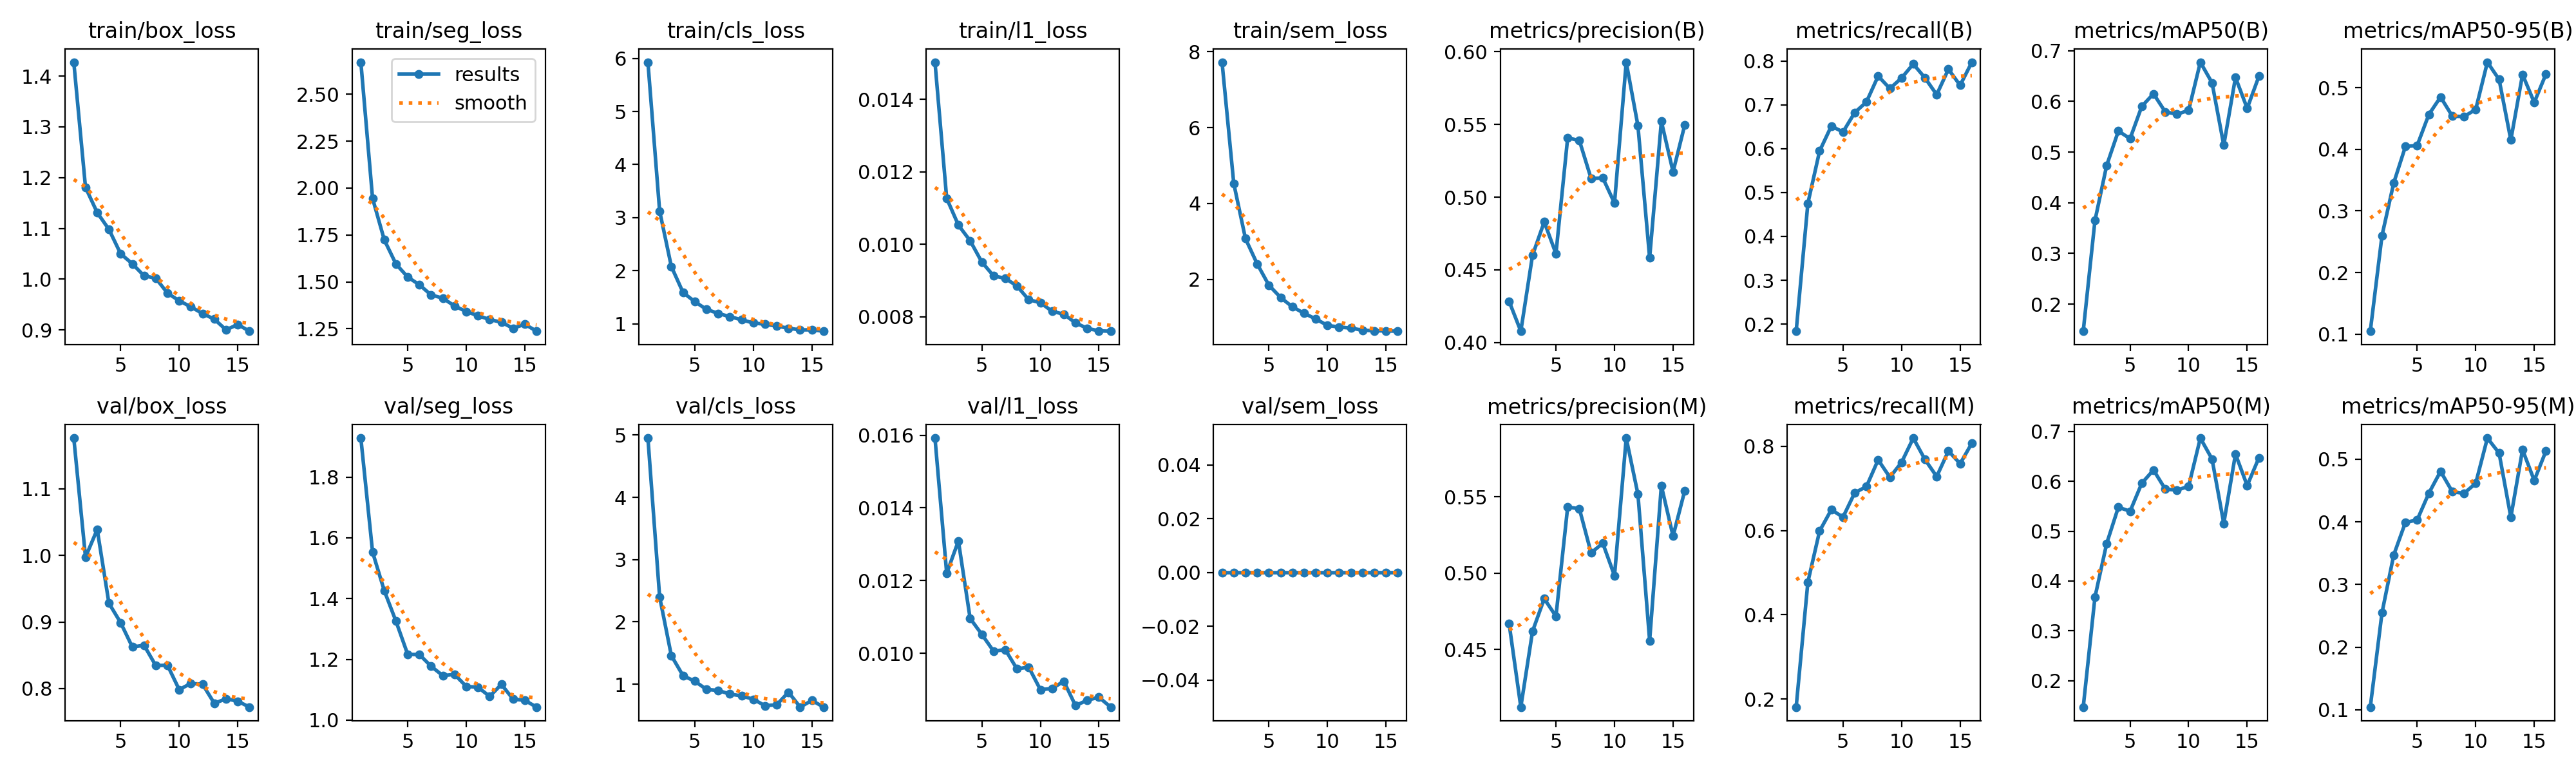

,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/l1_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),...,metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/l1_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
11,12,830.942,0.93235,1.29958,0.95647,0.00807,0.72078,0.54909,0.76175,0.63686,...,0.64464,0.50953,0.80642,1.07792,0.66920,0.00923,0,0.000236,0.000236,0.000236
12,13,898.479,0.92146,1.28526,0.91663,0.00783,0.66491,0.45822,0.72351,0.51361,...,0.51545,0.40728,0.77785,1.11753,0.87207,0.00856,0,0.000223,0.000223,0.000223
13,14,966.124,0.90033,1.25284,0.88475,0.00768,0.64925,0.55211,0.78171,0.64745,...,0.65474,0.51496,0.78478,1.06882,0.63241,0.00871,0,0.000211,0.000211,0.000211
14,15,1033.960,0.91090,1.27468,0.88634,0.00761,0.64705,0.51746,0.74485,0.58634,...,0.59140,0.46590,0.78107,1.06502,0.73947,0.00879,0,0.000199,0.000199,0.000199
15,16,1101.800,0.89768,1.23734,0.85992,0.00760,0.63853,0.54966,0.79765,0.64966,...,0.64723,0.51309,0.77227,1.04277,0.63321,0.00852,0,0.000187,0.000187,0.000187


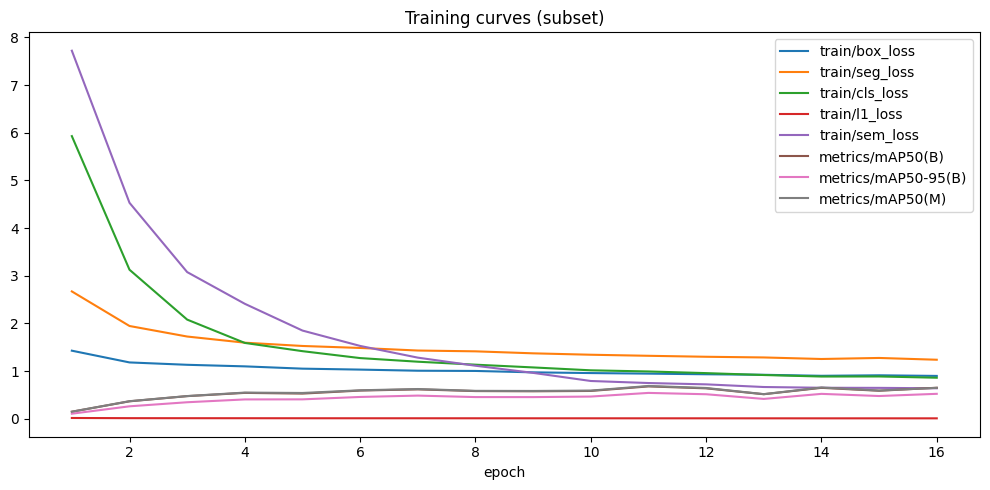

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.display import Image as IPImage

# Ultralytics writes under project/name (and may append a suffix if exist_ok=False)
RUN_DIR = Path(ft_model.trainer.save_dir)
print("Run directory:", RUN_DIR)
print("Weights:", list((RUN_DIR / "weights").glob("*.pt")))

results_png = RUN_DIR / "results.png"
results_csv = RUN_DIR / "results.csv"

if results_png.exists():
    display(IPImage(filename=str(results_png)))
else:
    print("results.png not found yet")

if results_csv.exists():
    curves = pd.read_csv(results_csv)
    curves.columns = [c.strip() for c in curves.columns]
    display(curves.tail())

    # Plot a few key columns if present
    plot_cols = [c for c in curves.columns if any(k in c for k in ("map", "mAP", "loss", "precision", "recall"))]
    # Prefer a compact set
    preferred = [c for c in curves.columns if c in {
        "epoch",
        "metrics/mAP50(B)", "metrics/mAP50-95(B)",
        "metrics/mAP50(M)", "metrics/mAP50-95(M)",
        "metrics/mAP50(P)", "metrics/mAP50-95(P)",
        "train/box_loss", "val/box_loss",
        "train/cls_loss", "val/cls_loss",
        "train/dfl_loss", "val/dfl_loss",
        "train/pose_loss", "val/pose_loss",
        "train/kobj_loss", "val/kobj_loss",
        "train/seg_loss", "val/seg_loss",
    } or "mAP50" in c or c.endswith("_loss")]

    cols_to_plot = [c for c in preferred if c != "epoch" and c in curves.columns]
    if cols_to_plot:
        ax = curves.plot(x="epoch" if "epoch" in curves.columns else None, y=cols_to_plot[:8], figsize=(10, 5))
        ax.set_title("Training curves (subset)")
        plt.tight_layout()
        plt.show()

In [ ]:
# Confirm the fine-tuned model now uses the dataset class names
best_path = RUN_DIR / "weights" / "best.pt"
assert best_path.exists(), f"Missing best.pt at {best_path}"

ft_best = YOLO(str(best_path))
print("Fine-tuned model class names:")
for i, name in ft_best.names.items():
    print(f"  {i}: {name}")

print("\nDataset class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")

print("\nNames match:", dict(ft_best.names) == dict(NAMES))

Fine-tuned model class names:
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}

Dataset class names:
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}
  {i}: {name}

Names match: True


### Checkpoint 3: Transfer learning did what you intended

**Write your answer below (your own words):**
- Find the line `Transferred X/Y items` in the training log. Which parts of the network could not be transferred from the pretrained model, and why?
- Do the fine-tuned model's class names now match the dataset?
- Justify your epoch choice using the training curves. Enough? Still improving? Any overfitting in validation losses?

**Task-specific:** None of the 23 car-part names exist in COCO. What does that mean for the layer that outputs class scores?

*(Your explanation here.)*


---
## Step 3: Evaluation

Evaluate **`best.pt`** (not `last.pt`) on the **test** split.


In [ ]:
# Honest evaluation on the held-out split specified by the lab
metrics = ft_best.val(
    data=DATA_YAML,
    split="test",
    imgsz=IMGSZ,
    plots=True,
)

print(metrics)

print("\n--- Box metrics ---")
print(f"box mAP50:     {metrics.box.map50:.4f}")
print(f"box mAP50-95:  {metrics.box.map:.4f}")

print("\n--- Mask metrics ---")
print(f"mask mAP50:     {metrics.seg.map50:.4f}")
print(f"mask mAP50-95:  {metrics.seg.map:.4f}")

print("\nPer-class mask AP50:")
for i, ap in enumerate(metrics.seg.ap50):
    print(f"  {NAMES[i]}: {ap:.4f}")


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,709,129 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1361.2±450.4 MB/s, size: 36.2 KB)
val: Scanning /content/datasets/carparts-seg/labels/test... 276 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 276/276 952.9it/s 0.3s
val: New cache created: /content/datasets/carparts-seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.0it/s 6.1s
                   all        276       1599      0.606      0.775      0.672      0.539      0.611      0.779      0.676      0.531
           back_bumper         44         44      0.749      0.864      0.849      0.635       0.75      0.864      0.849      0.686
             back_door         85         85      0.797       0.88      0.876       0.74      0.

### Results table

| Model | Epochs | Split | mAP50 | mAP50-95 |
| --- | --- | --- | --- | --- |
| Baseline (pretrained) | — | — | Not meaningful (see Checkpoint 2) | — |
| Fine-tuned (`best.pt`) |  | `test` |  |  |
| Fine-tuned box (`best.pt`) |  | `test` |  |  |
| Fine-tuned mask (`best.pt`) |  | `test` |  |  |

Fill in the blanks from the `val` output above.


### Checkpoint 4: Reading the metrics

**Write your answer below (your own words):**
- Report mAP50 and mAP50-95 (and fill the table).
- In one sentence, what does your mAP50 mean in plain language?
- Why is the test score a fairer measure than the validation score shown during training?

**Task-specific:** Report both box mAP and mask mAP. Why is mask mAP lower? Do left/right parts (e.g. `front_left_door` vs `front_right_door`) cause trouble? Why?

*(Your explanation here.)*


---
## Step 4: Real-world test

Use **three** images (or one clip ≤15s) from a free-license site (Pexels, Pixabay, Unsplash). Not from the dataset.


### Prediction 3 *(write BEFORE running inference)*

Which of your real-world images will be hardest for the model? Why?

*I predict that the 3rd real-world image will be the hardest, because it is of a racecar, something the model has not been trained on yet.*


In [ ]:
# Replace these with THREE free-license car image URLs (Pexels / Pixabay / Unsplash).
REAL_WORLD_SOURCES = [
    "https://pixabay.com/photos/opel-gt-antique-car-youngtimer-5190050/",
    "https://pixabay.com/images/download/x-4322521_1920.jpg",
    "https://pixabay.com/images/download/x-8136751_1920.jpg",
]

assert len(REAL_WORLD_SOURCES) >= 3, "Add at least 3 image URLs before running."

rw_results = show_predictions(ft_best, REAL_WORLD_SOURCES, title_prefix="real-world")


AssertionError: Add at least 3 image URLs before running.

### Checkpoint 5: Sources and results

**Write your answer below (your own words):**
- List each image's source URL and license.
- Was Prediction 3 right? What is different about real-world images vs. the dataset?

| # | Source URL | License | Notes |
| --- | --- | --- | --- |
| 1 |  |  |  |
| 2 |  |  |  |
| 3 |  |  |  |

*Prediction 3 was right(?). Real-world images **


---
## Step 5: Failure analysis

Find one honest failure of the fine-tuned model (missed object, wrong class, bad outline, or misplaced keypoints).


In [ ]:
# Helper: look for images with few/empty mask predictions vs. labels that have many parts.
candidate_pool = test_imgs if test_imgs else val_imgs
sample = random.Random(1).sample(candidate_pool, k=min(12, len(candidate_pool)))

fail_candidates = []
for p in sample:
    r = ft_best.predict(source=str(p), imgsz=IMGSZ, verbose=False)[0]
    n_pred = 0 if r.boxes is None else len(r.boxes)
    confs = [] if n_pred == 0 else r.boxes.conf.cpu().tolist()
    fail_candidates.append((p, n_pred, confs))

fail_candidates.sort(key=lambda t: (t[1] == 0, -(max(t[2]) if t[2] else -1)))

print("Candidates to inspect (path, n_pred, confs):")
for p, n_pred, confs in fail_candidates[:6]:
    print(f"  {Path(p).name}: n={n_pred}, confs={[round(c, 3) for c in confs]}")

fail_img = fail_candidates[0][0]
print("\nShowing:", fail_img)
_ = show_predictions(ft_best, [fail_img], title_prefix="failure")
_ = show_ground_truth([fail_img], NAMES, n=1, seed=0)


### Checkpoint 6: One honest failure

**Write your answer below (your own words):**
- Show/describe the failure case.
- Name the likely cause: small object, occlusion, unusual angle, lighting, out-of-distribution, or other.
- In 2–3 sentences, explain why that cause produced the failure.

*(Your explanation here.)*


---
## Reflection questions

Answer in your own words, using your results as evidence. **Do not use AI to write these.**


### Notebooks 1 and 2 — answer both

1. Compare your predictions with what actually happened. Which surprised you, and what did you learn from the surprise?

*(Your answer here.)*

2. In this task, what did transfer learning give you that the baseline couldn't?

*(Your answer here.)*


---
## AI log

Record important AI interactions (aim for 3–5 entries). Across the three notebooks, at least one entry must describe a case where the AI was wrong or incomplete.

| # | Step | What I needed | What I asked (summary) | What the AI gave me | What I did (accepted / modified / rejected) and why | How I verified it |
| --- | --- | --- | --- | --- | --- | --- |
| 1 |  |  |  |  |  |  |
| 2 |  |  |  |  |  |  |
| 3 |  |  |  |  |  |  |
| 4 |  |  |  |  |  |  |
| 5 |  |  |  |  |  |  |
